# Chapter 2 - Preprocessing, Pipelines and Hyperparameter Search

**Scenario:** a rental platform wants to predict the monthly rent of a new apartment before the listing is published.

The target is monthly_rent_eur. Keep apartment_rentals_students.csv in the same folder as this notebook.

## 0. Import libraries and dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.base import clone
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42

df = pd.read_csv("apartment_rentals_students.csv")

# Provided helper: return the main regression metrics for one fitted estimator.
def evaluate_regressor(name, estimator, X, y):
    predictions = estimator.predict(X)
    return {
        "model": name,
        "RMSE": mean_squared_error(y, predictions) ** 0.5,
        "MAE": mean_absolute_error(y, predictions),
        "R2": r2_score(y, predictions),
    }

# Provided helper: convert GridSearchCV results into a compact table.
def search_results_table(search, top_n=10):
    results = pd.DataFrame(search.cv_results_).copy()
    results["CV_RMSE"] = -results["mean_test_score"]
    results["TRAIN_RMSE"] = -results["mean_train_score"]
    results["CV_STD"] = results["std_test_score"]
    columns = [
        "rank_test_score", "CV_RMSE", "CV_STD", "TRAIN_RMSE", "params"
    ]
    return results.sort_values("rank_test_score")[columns].head(top_n)

df.head()

,listing_id,size_m2,num_rooms,floor,distance_to_center_km,building_age_years,furnished,property_type,heating_type,condition,energy_rating,neighborhood,monthly_rent_eur
0,L00001,54.2,2,2,7.9,7,no,apartment,heat_pump,excellent,B,Area_10,1472
1,L00002,100.9,3,2,3.7,41,no,apartment,electric,good,E,Area_02,1847
2,L00003,76.0,3,8,2.8,28,yes,studio,gas,fair,C,Area_15,1770
3,L00004,67.1,2,3,3.9,11,no,apartment,gas,fair,D,Area_07,1559
4,L00005,72.0,2,3,3.7,49,yes,apartment,electric,excellent,B,Area_01,1625


## 1. Understand the dataset

As in the previous practice, the prediction must be made before the apartment is published, using only the information in the listing.

Start by inspecting the data:

In [2]:
print("Shape:", df.shape)

display(
    pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_unique": df.nunique(),
        "missing": df.isna().sum(),
    })
)

display(df.describe(include="all").T)

Shape: (1000, 13)


,dtype,n_unique,missing
listing_id,str,1000,0
size_m2,float64,615,0
num_rooms,int64,6,0
floor,int64,10,0
distance_to_center_km,float64,165,0
building_age_years,int64,99,0
furnished,str,2,0
property_type,str,3,0
heating_type,str,4,0
condition,str,4,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
listing_id,1000,1000,L00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
size_m2,1000.0,NaN,NaN,NaN,73.3905,27.22726,25.0,54.575,73.9,92.225,156.6
num_rooms,1000.0,NaN,NaN,NaN,2.666,1.174659,1.0,2.0,3.0,3.0,6.0
floor,1000.0,NaN,NaN,NaN,2.941,1.723511,0.0,2.0,3.0,4.0,9.0
distance_to_center_km,1000.0,NaN,NaN,NaN,6.0,3.904962,0.3,3.1,5.1,8.0,20.0
building_age_years,1000.0,NaN,NaN,NaN,34.632,23.409498,0.0,16.75,30.0,48.0,100.0
furnished,1000,2,no,641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
property_type,1000,3,apartment,726,NaN,NaN,NaN,NaN,NaN,NaN,NaN
heating_type,1000,4,gas,355,NaN,NaN,NaN,NaN,NaN,NaN,NaN
condition,1000,4,good,499,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Data dictionary

| Variable | Meaning |
|---|---|
| `listing_id` | Listing identifier |
| `size_m2` | Apartment size in square metres |
| `num_rooms` | Number of rooms |
| `floor` | Floor number |
| `distance_to_center_km` | Distance to the city centre |
| `building_age_years` | Building age |
| `furnished` | Whether the apartment is furnished |
| `property_type` | Studio, apartment or duplex |
| `heating_type` | Main heating system |
| `condition` | Physical condition of the property |
| `energy_rating` | Energy efficiency rating |
| `neighborhood` | Neighborhood name |
| `monthly_rent_eur` | Monthly rent to predict |

In [3]:
df.dtypes

listing_id                   str
size_m2                  float64
num_rooms                  int64
floor                      int64
distance_to_center_km    float64
building_age_years         int64
furnished                    str
property_type                str
heating_type                 str
condition                    str
energy_rating                str
neighborhood                 str
monthly_rent_eur           int64
dtype: object

## 2. Define feature roles

TODO - Complete the groups below.

```text
Identifier columns: `listing_id`

Target: `monthly_rent_eur`

Numerical features: `size_m2`, `num_rooms`, `distance_to_center_km`, `building_age_years`, `floor`

Nominal categorical features: `furnished`, `heating_type`, `property_type`

Ordinal categorical features: `energy_rating`, `condition`

High-cardinality categorical features: `neighborhood`
```

Nominal features: no podemos ordenar los barrios de Madrid

Ordinales: sí podemos ordenarlos. Ej: Estado Malo, Estado intermedio, Estado Bueno

High-cardinality categorical values: para variables categóricas que toman muchos posibles valores. Si hacemos un OneHotEncoding normal, añadioms demasiadas columnas. En lugar de eso, agrupamos los valores que aparecen poco.

In [4]:
# TODO: define the role of each column.

id_columns = [
    "listing_id"
]

target = "monthly_rent_eur"

numeric_features = [
    "size_m2",
    "num_rooms",
    "distance_to_center_km",
    "building_age_years",
    "floor"
]

nominal_features = [
    "furnished",
    "heating_type",
    "property_type"
]

ordinal_features = [
    "condition",
    "energy_rating"
]

high_cardinality_features = [
    "neighborhood"
]

# Build X and y only after defining the roles.
X = df.drop(columns=id_columns + [target])
y = df[target]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1000, 11)
y shape: (1000,)


TODO - Write a short justification:

```text
The variable(s) that require ordinal encoding are `energy_rating` and `condition` because 
    - A second floor is higher than a first floor
    - A-rating is better than B-rating
    - excel"lent condicion is better than "good" condition

The variable(s) that require one-hot encoding are `furnished`, `heating_type`, `property_type` `neighborhood`* because they don't have any order

```

## 3. Apply a train / validation / test split

You already know this split from previous practices. Apply it here **before fitting any encoder or scaler**.

Use approximately:

```text
train       60%
validation  20%
test        20%
```

This is a regression problem, so there is no class label to stratify.

In [5]:
# TODO: first separate the final test set.
X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
)

# TODO: split the remaining data into train and validation.
X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.25,
    random_state=RANDOM_STATE,
)

pd.DataFrame({
    "split": ["train", "validation", "test"],
    "rows": [len(X_train), len(X_val), len(X_test)],
    "percentage": [len(X_train)/len(X), len(X_val)/len(X), len(X_test)/len(X)],
})

,split,rows,percentage
0,train,600,0.6
1,validation,200,0.2
2,test,200,0.2


TODO - Write one sentence:

```text
Encoders and scalers must be fitted after the split because each group has a different \mu and \sigma.
```

## 4. Nominal categorical variables: One-Hot Encoding

With the standard one-hot representation used here, **each observed category becomes its own binary column**.

handle_unknown="ignore" is important because validation or test data may contain a category that was absent from the training set.

In [6]:
# TODO: create a OneHotEncoder for the low-cardinality nominal variables.
# Keep one output column per category and allow unknown categories at transform time.

nominal_features = [
    "furnished",
    "heating_type",
    "property_type"
]

nominal_encoder = OneHotEncoder(
    handle_unknown="ignore",
    drop=None, # None retain all features. 1 columna por categoría. (Según la documentación)
    sparse_output=False,
)

# Fit only on the training data.
nominal_encoded = nominal_encoder.fit_transform(X_train[nominal_features])

nominal_encoded_df = pd.DataFrame(
    nominal_encoded,
    columns=nominal_encoder.get_feature_names_out(nominal_features),
    index=X_train.index,
)

nominal_encoded_df.head()

,furnished_no,furnished_yes,heating_type_central,heating_type_electric,heating_type_gas,heating_type_heat_pump,property_type_apartment,property_type_duplex,property_type_studio
876,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
326,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
381,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
853,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
311,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0


Aquí solo pones data del train (no del validation).

TODO - Write a short interpretation:

```text
The original nominal variables generated 9 encoded columns = furnished yes/no, heating central/electric/gas/pump, property apartment/duplex/studio

I would not encode property_type as 0, 1, 2 because it would not fit the size of the other columns. (It would be an artificial order)
```

## 5. Ordered categorical variables: Ordinal Encoding

Ordinal variables are different: their categories have a real order. OrdinalEncoder can preserve that order by mapping each category to an ordered numeric value.

Do not let the encoder infer an order alphabetically: define the domain order explicitly.

In [7]:
ordinal_features = [
    "condition",
    "energy_rating"
]

df["condition"].unique()

<StringArray>
['excellent', 'good', 'fair', 'needs_renovation']
Length: 4, dtype: str

In [8]:
# TODO: define the two category orders from worst to best.
condition_order = ["needs_renovation", "fair", "good", "excellent"]
energy_order = ['G', 'F', 'E', 'D', 'C', 'B', 'A']

# TODO: create the encoder.
ordinal_encoder = OrdinalEncoder(
    categories=[condition_order, energy_order],
    handle_unknown="use_encoded_value",
    unknown_value=-1,
)

ordinal_encoded = ordinal_encoder.fit_transform(X_train[ordinal_features])

pd.DataFrame(
    ordinal_encoded,
    columns=ordinal_features,
    index=X_train.index,
).head(10)

,condition,energy_rating
876,1.0,4.0
326,1.0,4.0
381,2.0,3.0
853,2.0,2.0
311,2.0,2.0
306,3.0,4.0
490,2.0,2.0
719,3.0,3.0
912,1.0,3.0
374,1.0,4.0


TODO - Write a short interpretation:

```text
Ordinal encoding is appropriate here because variables relate with an specific order.

An arbitrary alphabetical order would be problematic because the prediction model needs an array of numbers as input.
```

## 6. High-cardinality categorical variables

One-hot encoding is easy to interpret, but a categorical variable with many values can create too many columns.

Inspect neighborhood first.

Number of neighborhoods in train: 29


,count
neighborhood,
Area_01,190
Area_02,78
Area_03,45
Area_04,36
Area_05,31
Area_06,21
Area_10,21
Area_07,18
Area_09,17


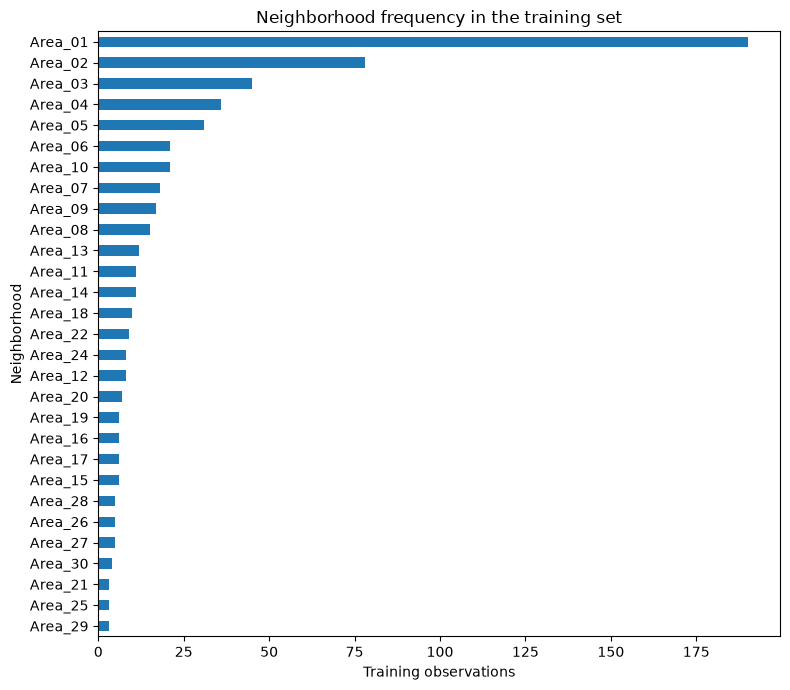

In [9]:
neighborhood_counts = X_train["neighborhood"].value_counts()

print("Number of neighborhoods in train:", neighborhood_counts.size)
display(neighborhood_counts.to_frame("count"))

ax = neighborhood_counts.sort_values(ascending=True).plot(
    kind="barh", figsize=(8, 7), legend=False
)
ax.set_xlabel("Training observations")
ax.set_ylabel("Neighborhood")
ax.set_title("Neighborhood frequency in the training set")
plt.tight_layout()
plt.show()

In [10]:
# TODO: fit a naive one-hot encoder to neighborhood.
naive_neighborhood_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False,
)

naive_neighborhood_encoder.fit(X_train[["neighborhood"]])
naive_columns = naive_neighborhood_encoder.get_feature_names_out(["neighborhood"])

# TODO: create a second encoder that groups categories appearing fewer than 20 times.
grouped_neighborhood_encoder = OneHotEncoder(
    handle_unknown='ignore',
    min_frequency=20,
    sparse_output=False,
)

grouped_neighborhood_encoder.fit(X_train[["neighborhood"]])
grouped_columns = grouped_neighborhood_encoder.get_feature_names_out(["neighborhood"])

pd.DataFrame({
    "encoding": ["one column per category", "group infrequent categories"],
    "output_columns": [naive_columns, grouped_columns],
})

,encoding,output_columns
0,one column per category,"[neighborhood_Area_01, neighborhood_Area_02, n..."
1,group infrequent categories,"[neighborhood_Area_01, neighborhood_Area_02, n..."


TODO - Write a short interpretation:

```text
Without grouping, neighborhood creates 30 columns.
With min_frequency=20, it creates 8 columns.

Grouping rare categories can help because they become more manageable
The trade-off is loosing individual information
```

## 7. Numerical variables and scaling

Different models use numerical values differently.

KNN is based on distances. If one variable spans 0–180 and another 0–20, the first can dominate the distance simply because of its units.

Tree-based models do not compare Euclidean distances, so scaling is generally **unnecessary** for Decision Trees and Random Forests.

Inspect the numerical scales in the training set.

In [11]:
X_train[numeric_features].agg(["min", "max", "mean", "std"]).T

,min,max,mean,std
size_m2,25.0,141.5,73.226000,26.227343
num_rooms,1.0,6.0,2.631667,1.117174
distance_to_center_km,0.3,20.0,5.919500,3.767704
building_age_years,1.0,100.0,34.258333,23.394738
floor,0.0,9.0,2.923333,1.706549


StandardScaler learns a mean and standard deviation **from the training data** and transforms each value so that the column has mean 0 and standard deviation 1.

For KNN we will scale numerical features. For the tree models we will leave them unchanged.

In [12]:
# TODO: fit StandardScaler only on the numerical training columns.
scaler = StandardScaler()
scaled_numeric = scaler.fit_transform(X_train[numeric_features])

scaled_numeric_df = pd.DataFrame(
    scaled_numeric,
    columns=numeric_features,
    index=X_train.index,
)

scaled_numeric_df.agg(["mean", "std"]).T

,mean,std
size_m2,4.736952e-17,1.000834
num_rooms,-1.894781e-16,1.000834
distance_to_center_km,-5.033011e-17,1.000834
building_age_years,3.996803e-17,1.000834
floor,-2.960595e-17,1.000834


TODO - Write a short interpretation:

```text
Scaling is important for KNN because it compares euclidean distances

I would not expect scaling to materially change a Decision Tree because it does not compare euclidean distances
```

## 8. Combine transformations with `ColumnTransformer`

So far each group of columns has been transformed separately for educational purposes. In a real modelling workflow we want a single object that knows what to do with each group.

`ColumnTransformer` applies different transformers to different columns and concatenates the outputs.

We will build **two preprocessing strategies**:

```text
KNN preprocessing
- numerical       -> StandardScaler
- nominal          -> OneHotEncoder
- ordinal          -> OrdinalEncoder + StandardScaler
- neighborhood     -> OneHotEncoder with infrequent-category grouping

Tree preprocessing
- numerical        -> passthrough
- nominal          -> OneHotEncoder
- ordinal          -> OrdinalEncoder
- neighborhood     -> OneHotEncoder with infrequent-category grouping
```

The difference is deliberate: distance-based models need comparable scales; trees do not.

In [13]:
# TODO: create the preprocessing blocks used by KNN.
knn_numeric = Pipeline([
    ("scaler", scaler),
])

knn_ordinal = Pipeline([
    ("encoder", OrdinalEncoder(
        categories=[condition_order, energy_order],
        handle_unknown="use_encoded_value",
        unknown_value=-1,
    )),
    ("scaler", scaler),
])

knn_preprocessor = ColumnTransformer([
    ("numeric", scaler, numeric_features),
    ("nominal", nominal_encoder, nominal_features),
    ("ordinal", ordinal_encoder, ordinal_features),
    ("high_card", OneHotEncoder(
        handle_unknown="infrequent_if_exist",
        min_frequency=20,
    ), high_cardinality_features),
])

# TODO: create the preprocessing used by Decision Trees and Random Forests.
tree_preprocessor = ColumnTransformer([
    ("numeric", "passthrough", numeric_features),
    ("nominal", OneHotEncoder(handle_unknown="ignore"), nominal_features),
    ("ordinal", OrdinalEncoder(
        categories=[condition_order, energy_order],
        handle_unknown="use_encoded_value",
        unknown_value=-1,
    ), ordinal_features),
    ("high_card", OneHotEncoder(
        handle_unknown="infrequent_if_exist",
        min_frequency=20,
    ), high_cardinality_features),
])

## 9. From preprocessing to a `Pipeline`

A Pipeline chains preprocessing and model fitting into one estimator:

```text
raw X
  ↓
ColumnTransformer
  ↓
model-ready matrix
  ↓
regressor
```

This is not just convenient. During cross-validation, the preprocessing is fitted separately inside every training fold, so validation rows do not influence means, standard deviations, categories or frequency thresholds.

It also lets us tune preprocessing and model hyperparameters together.

In [14]:
# TODO: build one pipeline for each model family.

knn_pipeline = Pipeline([
    ("preprocessing", knn_preprocessor),
    ("model", KNeighborsRegressor()),
])

tree_pipeline = Pipeline([
    ("preprocessing", tree_preprocessor),
    ("model", DecisionTreeRegressor(random_state=RANDOM_STATE)),
])

rf_pipeline = Pipeline([
    ("preprocessing", tree_preprocessor),
    ("model", RandomForestRegressor(
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])

## 10. Hyperparameter search with cross-validation

Finally, use GridSearchCV on the **training set only**. The validation and test sets remain untouched.

We will optimize RMSE. Because scikit-learn maximizes scores, the scoring name is `neg_root_mean_squared_error`; the helper table converts it back to a positive RMSE.

Pipeline parameters use the syntax:

```text
step__parameter
```

For example:

```text
model__n_neighbors
preprocessing__high_card__min_frequency
```

This means a search can tune both the model and a preprocessing decision.

### 10.1 KNN

Define a small but meaningful grid.

Guidelines:

- n_neighbors: try several values from very local to smoother models; for this dataset, 3–30 is a sensible introductory range.
- weights: include both "uniform" and "distance".
- p: "1" gives Manhattan distance and "2" Euclidean distance.
- also try at least two values for the neighborhood "min_frequency" threshold.

In [15]:
# TODO: choose candidate values. Do not use an excessively large grid.
knn_param_grid = {
    "model__n_neighbors": [i for i in range(3,31)],
    "model__weights": ["uniform", "distance"],
    "model__p": [1,2],
    "preprocessing__high_card__min_frequency": [20,25],
}

# TODO: configure a 5-fold GridSearchCV using RMSE.
knn_search = GridSearchCV(
    estimator=knn_pipeline, # pipeline prviously declared
    param_grid=knn_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    return_train_score=True,
)

knn_search.fit(X_train, y_train)
pd.set_option('display.max_colwidth', None)
search_results_table(knn_search, top_n=20)

,rank_test_score,CV_RMSE,CV_STD,TRAIN_RMSE,params
71,1,284.410139,11.378957,0.000041,"{'model__n_neighbors': 11, 'model__p': 2, 'model__weights': 'distance', 'preprocessing__high_card__min_frequency': 25}"
79,2,284.625385,12.839425,0.000044,"{'model__n_neighbors': 12, 'model__p': 2, 'model__weights': 'distance', 'preprocessing__high_card__min_frequency': 25}"
70,3,284.627866,12.522975,0.000042,"{'model__n_neighbors': 11, 'model__p': 2, 'model__weights': 'distance', 'preprocessing__high_card__min_frequency': 20}"
62,4,284.734866,11.609619,0.000038,"{'model__n_neighbors': 10, 'model__p': 2, 'model__weights': 'distance', 'preprocessing__high_card__min_frequency': 20}"
63,5,285.361420,11.521511,0.000037,"{'model__n_neighbors': 10, 'model__p': 2, 'model__weights': 'distance', 'preprocessing__high_card__min_frequency': 25}"
78,6,285.394051,12.258548,0.000045,"{'model__n_neighbors': 12, 'model__p': 2, 'model__weights': 'distance', 'preprocessing__high_card__min_frequency': 20}"
46,7,285.399358,9.912322,0.000031,"{'model__n_neighbors': 8, 'model__p': 2, 'model__weights': 'distance', 'preprocessing__high_card__min_frequency': 20}"
54,8,285.430281,10.841392,0.000034,"{'model__n_neighbors': 9, 'model__p': 2, 'model__weights': 'distance', 'preprocessing__high_card__min_frequency': 20}"
87,9,285.705165,12.703962,0.000048,"{'model__n_neighbors': 13, 'model__p': 2, 'model__weights': 'distance', 'preprocessing__high_card__min_frequency': 25}"
60,10,285.820797,12.136091,256.403122,"{'model__n_neighbors': 10, 'model__p': 2, 'model__weights': 'uniform', 'preprocessing__high_card__min_frequency': 20}"


TODO - Interpret the KNN search briefly:

```text
Best hyperparameters: {'model__n_neighbors': 10, 'model__p': 2, 'model__weights': 'uniform', 'preprocessing__high_card__min_frequency': 20}

Best mean CV RMSE: 285.820797

The values of n_neighbors that performed best suggest that around 10 neighbours is a good choice.

The difference between TRAIN_RMSE and CV_RMSE suggests that in this case there is no overfitting, as it is on 1-19
```

### 10.2 Decision Tree

Guidelines:

- max_depth: include "None" and several moderate depths.
- min_samples_leaf: include "1" and several larger values.
- the neighborhood grouping threshold can also be part of the search.

Keep the grid compact enough to understand the combinations you are testing.

In [16]:
# TODO: define candidate values.
tree_param_grid = {
    "model__max_depth": [None, 5, 10, 15],
    "model__min_samples_leaf": [1, 5, 10, 20],
    "preprocessing__high_card__min_frequency": [20, 25],
}

# TODO: configure and run the search.
tree_search = GridSearchCV(
    estimator=tree_pipeline,
    param_grid=tree_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    return_train_score=True,
)

tree_search.fit(X_train, y_train)
pd.set_option('display.max_colwidth', None)
search_results_table(tree_search, top_n=20)

,rank_test_score,CV_RMSE,CV_STD,TRAIN_RMSE,params
27,1,297.551438,16.069222,171.532783,"{'model__max_depth': 15, 'model__min_samples_leaf': 5, 'preprocessing__high_card__min_frequency': 25}"
3,1,297.551438,16.069222,171.532783,"{'model__max_depth': None, 'model__min_samples_leaf': 5, 'preprocessing__high_card__min_frequency': 25}"
19,3,298.446304,16.980360,173.211026,"{'model__max_depth': 10, 'model__min_samples_leaf': 5, 'preprocessing__high_card__min_frequency': 25}"
31,4,299.305776,16.991573,252.044983,"{'model__max_depth': 15, 'model__min_samples_leaf': 20, 'preprocessing__high_card__min_frequency': 25}"
23,4,299.305776,16.991573,252.044983,"{'model__max_depth': 10, 'model__min_samples_leaf': 20, 'preprocessing__high_card__min_frequency': 25}"
7,4,299.305776,16.991573,252.044983,"{'model__max_depth': None, 'model__min_samples_leaf': 20, 'preprocessing__high_card__min_frequency': 25}"
15,7,299.798652,17.370744,253.142910,"{'model__max_depth': 5, 'model__min_samples_leaf': 20, 'preprocessing__high_card__min_frequency': 25}"
26,8,300.696875,16.981459,171.622423,"{'model__max_depth': 15, 'model__min_samples_leaf': 5, 'preprocessing__high_card__min_frequency': 20}"
2,8,300.696875,16.981459,171.622423,"{'model__max_depth': None, 'model__min_samples_leaf': 5, 'preprocessing__high_card__min_frequency': 20}"
18,10,300.744072,17.905408,173.522321,"{'model__max_depth': 10, 'model__min_samples_leaf': 5, 'preprocessing__high_card__min_frequency': 20}"


TODO - Interpret the Decision Tree search briefly:

```text
Best hyperparameters: {'model__max_depth': 15, 'model__min_samples_leaf': 20, 'preprocessing__high_card__min_frequency': 25} (first with no overfitting, the 4th one)

Best mean CV RMSE: 299.305776

The effect of max_depth / min_samples_leaf appears to be potentially making overfitting

Evidence of overfitting can be seen when the difference between TRAIN_RMSE and CV_RMSE is significant.
```

### 10.3 Random Forest

Guidelines:

- n_estimators: more trees generally stabilize the average, but computation increases. Try 2–3 values rather than dozens.
- max_depth: include "None" and one or two constrained depths.
- min_samples_leaf: compare very small leaves with a more regularized alternative.
- max_features: compare a random subset such as "sqrt" with a larger fraction such as "0.7" or "1.0".
- include at least two "min_frequency" values for the high-cardinality feature.

In [18]:
# TODO: define a compact Random Forest grid.
rf_param_grid = {
    "model__n_estimators": [100,250,500],
    "model__max_depth": [None, 10,15],
    "model__min_samples_leaf": [1,2,10,20],
    "model__max_features": ["sqrt", 0.7, 1],
    "preprocessing__high_card__min_frequency": [20,30],
}

# TODO: configure and run the search.
rf_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    return_train_score=True,
)

rf_search.fit(X_train, y_train)
pd.set_option('display.max_colwidth', None)
search_results_table(rf_search, top_n=50)

,rank_test_score,CV_RMSE,CV_STD,TRAIN_RMSE,params
172,1,234.942568,13.361041,87.633339,"{'model__max_depth': 15, 'model__max_features': 0.7, 'model__min_samples_leaf': 1, 'model__n_estimators': 500, 'preprocessing__high_card__min_frequency': 20}"
170,2,235.415562,13.319008,87.808482,"{'model__max_depth': 15, 'model__max_features': 0.7, 'model__min_samples_leaf': 1, 'model__n_estimators': 250, 'preprocessing__high_card__min_frequency': 20}"
28,3,235.707891,13.461972,87.197327,"{'model__max_depth': None, 'model__max_features': 0.7, 'model__min_samples_leaf': 1, 'model__n_estimators': 500, 'preprocessing__high_card__min_frequency': 20}"
168,4,235.935475,13.293125,89.522490,"{'model__max_depth': 15, 'model__max_features': 0.7, 'model__min_samples_leaf': 1, 'model__n_estimators': 100, 'preprocessing__high_card__min_frequency': 20}"
26,5,236.145794,13.003545,87.375706,"{'model__max_depth': None, 'model__max_features': 0.7, 'model__min_samples_leaf': 1, 'model__n_estimators': 250, 'preprocessing__high_card__min_frequency': 20}"
24,6,236.184694,13.240910,89.202396,"{'model__max_depth': None, 'model__max_features': 0.7, 'model__min_samples_leaf': 1, 'model__n_estimators': 100, 'preprocessing__high_card__min_frequency': 20}"
171,7,236.852533,15.312796,88.073618,"{'model__max_depth': 15, 'model__max_features': 0.7, 'model__min_samples_leaf': 1, 'model__n_estimators': 250, 'preprocessing__high_card__min_frequency': 30}"
100,8,237.454135,14.447483,101.799090,"{'model__max_depth': 10, 'model__max_features': 0.7, 'model__min_samples_leaf': 1, 'model__n_estimators': 500, 'preprocessing__high_card__min_frequency': 20}"
27,9,237.674456,14.210851,88.128104,"{'model__max_depth': None, 'model__max_features': 0.7, 'model__min_samples_leaf': 1, 'model__n_estimators': 250, 'preprocessing__high_card__min_frequency': 30}"
173,10,237.844450,14.867855,88.000476,"{'model__max_depth': 15, 'model__max_features': 0.7, 'model__min_samples_leaf': 1, 'model__n_estimators': 500, 'preprocessing__high_card__min_frequency': 30}"


TODO - Interpret the Random Forest search briefly:

```text
Best hyperparameters:

Best mean CV RMSE:

The hyperparameter(s) that appear to have the largest effect are ...

Changing n_estimators affected performance / stability by ...
```

## 11. Compare the selected pipelines on validation data

Each search has selected one configuration using cross-validation on the training set.

Now evaluate those three fixed configurations on the validation set. Do not tune anything using the test set.

In [ ]:
# TODO: evaluate each best estimator on validation data.
validation_results = pd.DataFrame([
    evaluate_regressor("KNN", knn_search, X_val, y_val),
    evaluate_regressor("Decision Tree", tree_search, X_val, y_val),
    evaluate_regressor("Random Forest", rf_search, X_val, y_val),
]).sort_values("RMSE")

validation_results

,model,RMSE,MAE,R2
2,Random Forest,238.987821,193.279197,0.771641
0,KNN,272.330037,218.913512,0.703477
1,Decision Tree,283.566380,225.019411,0.678503


TODO - Write a short interpretation:

```text
The model I would select is KNN (because I think RandomForest has overfitting)

Its validation RMSE is similar compared with its CV estimate of training

The agreement / disagreement between CV and validation suggests that ... agreement in KNN and decision tree suggests that the two models are generalizable

I would not choose a model only because its training error is lower because it depends of the dataset chosen.
```

## Alternative model-selection workflow

The workflow above uses cross-validation on the training set, validation data to compare the selected model families and the test set for the final evaluation.

An **equally valid alternative** would be to combine the training and validation sets into one development set, use cross-validation on that combined data to select the best model and hyperparameters, and keep the test set untouched until the final performance measurement. This approach allows the model-selection process to use more data, while preserving the test set as an unbiased final evaluation set.